# 第I部：移流方程式とBurgers方程式
## スカラー保存則から流体スキームを学ぶ

線形移流で「情報が伝わる方向」を、非粘性Burgers方程式で「伝播速度が解に依存する非線形性」を調べます。
**線形移流：一次風上差分・LF・LW。Burgers：Godunov・LF・LW。**
Roeのエントロピー補正なしの流束は、正しい解法の推奨ではなく、エントロピー条件の必要性を調べる反例に使います。

1. 保存則・セル平均・数値流束
2. 線形移流：風上差分、CFL条件、拡散・分散、収束次数
3. Burgers：特性曲線、衝撃波形成、弱解、衝撃波・希薄波
4. Godunov流束・保存性・エントロピー条件
5. Euler方程式との関係

[I 移流・Burgers](01_advection_burgers.ipynb) · [II Eulerの古典的解法](02_euler_classical.ipynb) · [III 近似リーマンソルバー](03_euler_riemann_solvers.ipynb) · [IV 空間再構築](04_spatial_reconstruction.ipynb) · [V 時間積分](05_time_integration.ipynb)

## 0. 設定と実行方法

リポジトリの `notebooks/` と `src/` の配置を保ち、上から実行してください。
数値計算は `src/scalar1d.py`、表の表示は `src/euler1d_study.py` を使います。
図のラベルは英語、解説は日本語です。計算量はすべて無次元です。
`run_movies` は時間発展動画、`run_extras` は追加のCFL実験と非保存形の反例を有効にします。

比較は**同じ方程式・初期条件・物理時刻・格子**で行います。Burgersの速度は解から決まり、方式ごとの時間刻みは同一とは限りません。

### 時間発展動画の問題を選択する

設定セルの `CFG["movie_case"]` に、次のいずれかの文字列を指定します。

| 設定する値 | 問題 | 主な観察点 |
|:--|:--|:--|
| `advection_sine` | 線形移流：正弦波 | 滑らかな波の数値拡散・位相誤差 |
| `advection_box` | 線形移流：矩形波 | 不連続面の拡散・非物理的振動 |
| `burgers_sine` | Burgers：滑らかな波の圧縮 | 非線形移流による波形の急峻化。標準の終了時刻では衝撃波形成前 |
| `burgers_shock` | Burgers：衝撃波（左1、右0） | Rankine–Hugoniot条件と衝撃波速度 |
| `burgers_rarefaction` | Burgers：希薄波（左−1、右1） | 希薄波、エントロピー条件、膨張衝撃波の問題 |

線形移流ではUpwind・LF・LW、Burgers方程式ではGodunov・LF・LWを比較します。Burgersの正弦波は標準設定の終了時刻 $t=0.4$ では衝撃波形成前です。

動画を無効にする場合は `CFG["run_movies"] = False` に設定してください。

In [1]:
from pathlib import Path
from dataclasses import replace
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/scalar1d.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("リポジトリ一式の notebooks/ と src/ を保って実行してください。")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
import scalar1d as sc
from euler1d_study import show_table

CFG = {
    "n": 200,
    "cfl": 0.4,
    "n_convergence": (50, 100, 200, 400),
    "run_convergence": True,
    "run_extras": False,
    "run_movies": True,
    "movie_case": "burgers_rarefaction",  # 選択肢は直前の表を参照
    "movie_frames": 41,
    "export_results": True,
}
RUNS = []
OUTPUT_DIR = ROOT / "four_part_outputs" / "scalar"
print(CFG)
checks = sc.run_tests()
print(f"Scalar tests passed: {len(checks)}")

{'n': 200, 'cfl': 0.4, 'n_convergence': (50, 100, 200, 400), 'run_convergence': True, 'run_extras': False, 'run_movies': True, 'movie_case': 'burgers_rarefaction', 'movie_frames': 41, 'export_results': True}
Scalar tests passed: 11


## 1. 保存則：流入と流出でセル平均が変わる

区間$[x_L,x_R]$に含まれる量が、その端を通る流束$f$で変化すると、

$$\frac{d}{dt}\int_{x_L}^{x_R}q\,dx=f(q(x_L,t))-f(q(x_R,t)),$$
$$\frac{\partial q}{\partial t}+\frac{\partial f(q)}{\partial x}=0.$$

格子上の未知量をセル平均$\bar q_i=\Delta x^{-1}\int_{x_{i-1/2}}^{x_{i+1/2}}q\,dx$とすると、

$$\bar q_i^{n+1}=\bar q_i^n-\frac{\Delta t}{\Delta x}(F^*_{i+1/2}-F^*_{i-1/2}).$$

**隣接セルが同じ境界流束を共有する**ため、セル間の寄与が打ち消し合います。周期境界では全量$\sum_i\bar q_i\Delta x$が保存され、開いた境界では境界流束との差が保存量の収支になります。[S1, S4]

コードの `numerical_flux` が境界流束を選び、`simulate` が上式で更新します。
初期値と誤差の基準にはセル平均を使います。図の黒線は見やすさのため点値の厳密解です。

## 2. 線形移流方程式と特性曲線

$$\frac{\partial q}{\partial t}+a \frac{\partial q}{\partial x}=0,\qquad f(q)=a q,\qquad q(x,t)=q_0(x-at).$$

$a$は一定です。$\frac{dx}{dt}=a$に沿って$\frac{dq}{dt}=0$となるので、値は直線$x=\xi+at$に沿って運ばれます。
したがって、波形のなまりや不自然な振動は物理現象ではなく数値誤差です。[S1]

$x-t$図では横軸が$x$、縦軸が$t$です。$a$は$\frac{dx}{dt}$であり、図で見える直線の傾き$\frac{dt}{dx}$とは逆数の関係です。
**確認：** $a$を負にすると情報はどちらへ伝わるでしょうか。

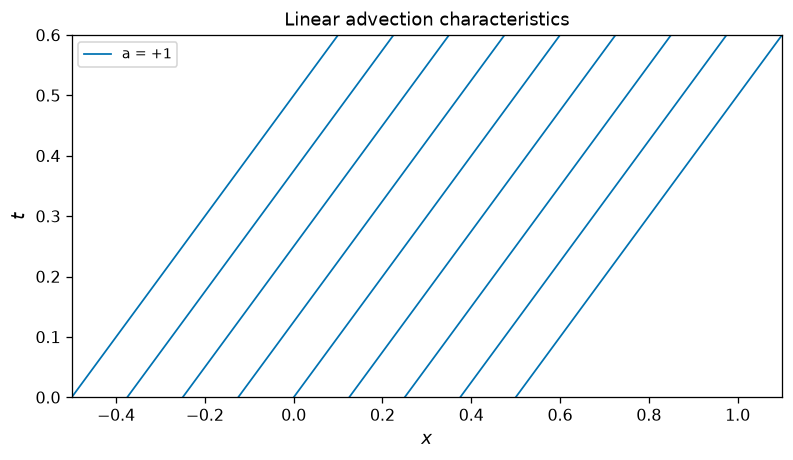

In [2]:
fig, ax = plt.subplots(figsize=(7.0, 4.1))
times = np.linspace(0.0, 0.6, 60)
for j, xi in enumerate(np.linspace(-0.5, 0.5, 9)):
    ax.plot(xi + times, times, color="#0072B2", lw=1.1, label="a = +1" if j == 0 else None)
ax.set(xlabel="$x$", ylabel="$t$", title="Linear advection characteristics", xlim=(-0.5, 1.1), ylim=(0.0, 0.6))
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

### 2.1 一次風上差分とCFL条件

$a>0$では左から情報が来るので、前進Euler時間積分と組み合わせて

$$\bar q_i^{n+1}=\bar q_i^n-C(\bar q_i^n-\bar q_{i-1}^n),\qquad C=\frac{a\Delta t}{\Delta x}.$$

$a<0$では右側を使います。両者をまとめた流束は

$$F^*_{i+1/2}=a^+q_L+a^-q_R=\frac{a}{2}(q_L+q_R)-\frac{|a|}{2}(q_R-q_L),\quad a^\pm=\frac{a\pm|a|}{2}.$$

$a>0$なら更新は$(1-C)\bar q_i+C\bar q_{i-1}$です。$0\le C\le1$のとき重みが非負で、新しい極大・極小を作りません。
$a<0$も含む安定条件は$|C|\le1$です。これは指定した**一次風上＋前進Euler**の条件です。

線形移流では区分一定Godunov法もこの更新になり、散逸係数を$|a|$としたLLF (Rusanov)流束とも一致します。[S2, S4]

**実装を読む：** `src/scalar1d.py` の `scheme == "Upwind"` では流束を速度の符号で切り替えます。

### 2.2 LFとLWを同じ保存形で書く

古典的Lax–Friedrichs法：

$$F^*_{\mathrm{LF}}=\frac{f(q_L)+f(q_R)}{2}-\frac{\Delta x}{2\Delta t}(q_R-q_L).$$

散逸係数は$\Delta x/\Delta t$です。局所波速を係数に使うLLFとは区別します。

Richtmyerの2段階Lax–Wendroff法：

$$q_{i+1/2}^{n+1/2}=\frac{q_L+q_R}{2}-\frac{\Delta t}{2\Delta x}(f(q_R)-f(q_L)),\qquad F^*_{\mathrm{LW}}=f(q_{i+1/2}^{n+1/2}).$$

線形移流では標準のLW更新

$$\bar q_i^{n+1}=\bar q_i^n-\frac C2(\bar q_{i+1}^n-\bar q_{i-1}^n)+\frac{C^2}{2}(\bar q_{i+1}^n-2\bar q_i^n+\bar q_{i-1}^n)$$

と一致します。滑らかな解に対して、一次風上とLFは1次、LWは2次精度です。LWは不連続付近で振動し得ます。[S2, S3]

一定の$C$で$\Delta t\propto\Delta x$とした修正方程式の主要な拡散係数は、

$$\nu_{\mathrm{up}}=\frac{|a|\Delta x}{2}(1-|C|),\qquad \nu_{\mathrm{LF}}=\frac{\Delta x^2}{2\Delta t}(1-C^2).$$

$0<|C|<1$ではどちらも正で、LFの方が大きくなります。LWではこの次数の拡散項が打ち消され、主要な誤差に3階空間微分の分散項が現れます。これは滑らかな解の局所展開であり、不連続面でのTaylor展開ではありません。[S3]

### 2.3 正弦波：振幅・位相・誤差

$0\le x\le1$、周期境界、$q_0=1+0.2\sin(2\pi x)$、$a=1$、$t=1$を使います。
格子セル内の正弦波を解析的に積分して初期値を与えます。

表の `L1` は平均$L_1$誤差、`balance` は境界流束を含む保存残差、`TV` は全変動です。
`undershoot`・`overshoot` は厳密解の値域からのはみ出しを表します。
**問い：** 最大値の低下と位相のずれを区別できますか。

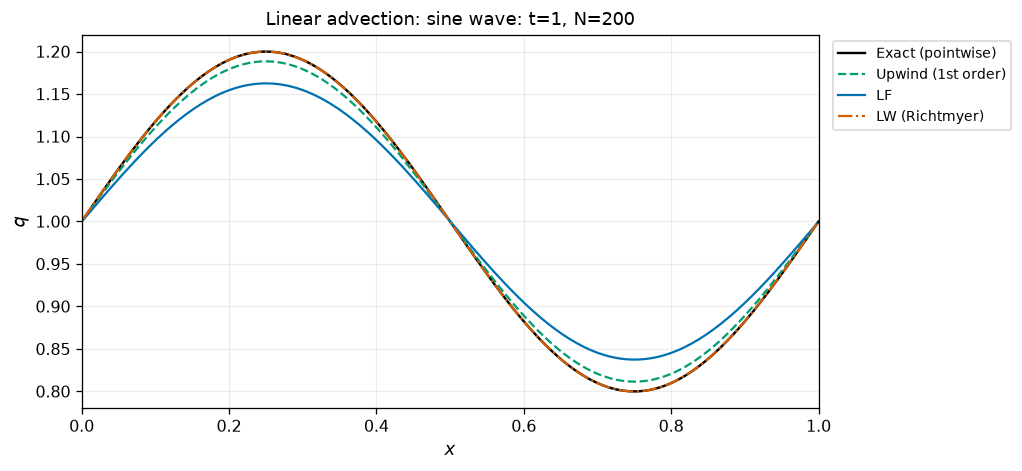

method,L1,amplitude_ratio,phase_error_rad,balance
Upwind (1st order),0.007321,0.9425,0.000124,0
LF,0.02384,0.8128,-0.001737,-2.842e-16
LW (Richtmyer),0.0001105,1,0.0008681,0


In [3]:
problem = sc.CASES["advection_sine"]
sine_runs = [sc.simulate(problem, method, n=CFG["n"], cfl=CFG["cfl"]) for method in ("Upwind", "LF", "LW")]
RUNS.extend(sine_runs)
sc.plot_profiles(sine_runs)
rows = []
for run in sine_runs:
    exact = sc.exact_cell_average(problem, run["edges"], run["t"])
    basis = np.exp(-2j * np.pi * run["x"])
    ratio = np.mean((run["q"] - 1.0) * basis) / np.mean((exact - 1.0) * basis)
    rows.append(dict(sc.metrics(run), amplitude_ratio=abs(ratio), phase_error_rad=np.angle(ratio)))
show_table(rows, ("method", "L1", "amplitude_ratio", "phase_error_rad", "balance"))

### 2.4 矩形波：正方向・負方向の移流

$q_0=1$を$0.25\le x<0.45$、それ以外を0とし、$t=0.25$まで進めます。
$a=1$と$a=-1$を別の図で比較します。周期境界を横切る矩形波も、セル内の占有率から厳密な平均値を計算します。

**問い：** 風上法が単調性を保つ代わりに失うものは何でしょうか。LWで負の値が現れても、ここでは自動的に0へ置き換えません。

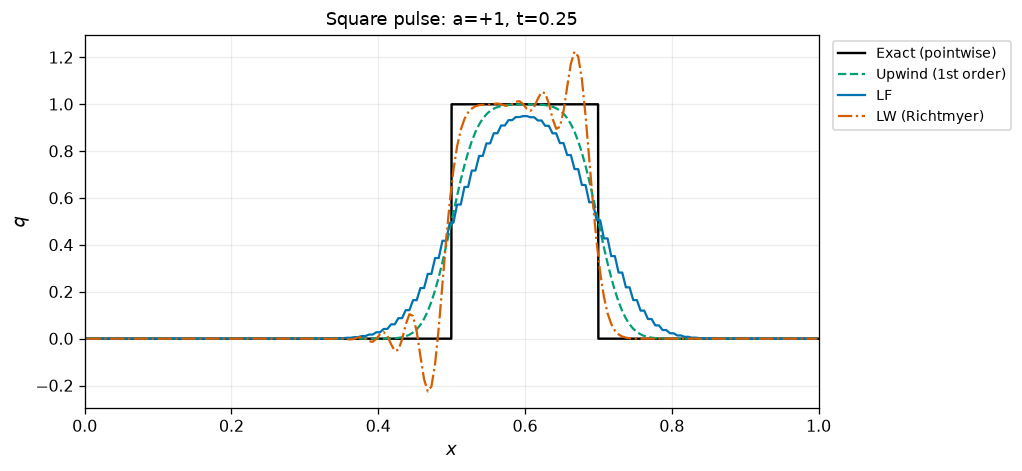

method,L1,TV,undershoot,overshoot,balance
Upwind (1st order),0.04361,2,0,0,0
LF,0.08194,1.899,0,0,0
LW (Richtmyer),0.03287,3.735,0.225,0.225,0


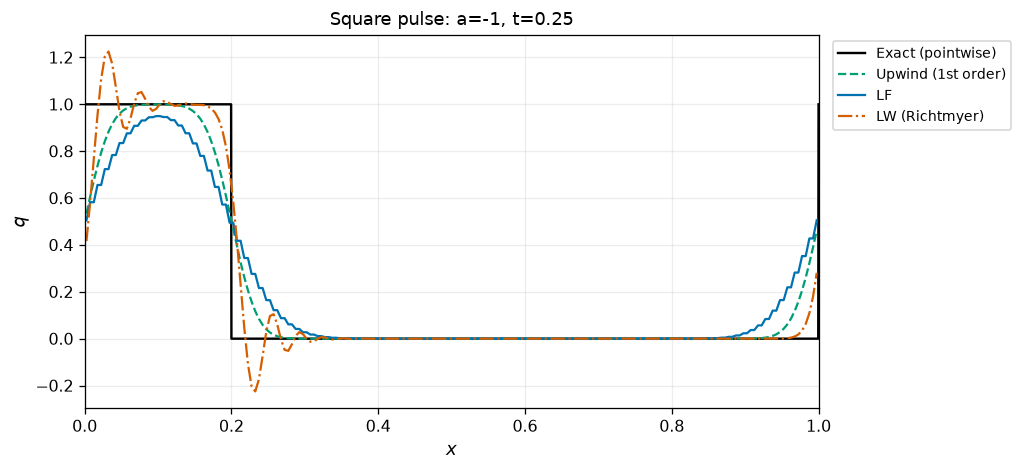

method,L1,TV,undershoot,overshoot,balance
Upwind (1st order),0.04361,2,0,0,3.553e-17
LF,0.08194,1.899,0,0,0
LW (Richtmyer),0.03287,3.735,0.225,0.225,-3.553e-17


In [4]:
for speed in (1.0, -1.0):
    problem = replace(sc.CASES["advection_box"], speed=speed)
    results = [sc.simulate(problem, method, n=CFG["n"], cfl=CFG["cfl"]) for method in ("Upwind", "LF", "LW")]
    RUNS.extend(results)
    sc.plot_profiles(results, title=f"Square pulse: a={speed:+g}, t={problem.final_time:g}")
    show_table([sc.metrics(r) for r in results], ("method", "L1", "TV", "undershoot", "overshoot", "balance"))

### 2.5 格子収束と$|C|=1$の特別な場合

正弦波で$N$を増やし、$p_{\mathrm{obs}}=\log(E_N/E_{2N})/\log2$を測ります。
矩形波には不連続があるため、滑らかな波と同じ収束次数を期待しないでください。

$C=+1$では、一次風上・LF・LWのすべてが$\bar q_i^{n+1}=\bar q_{i-1}^n$となります。
$C=-1$なら逆向きの1セル移動です。この特例だけでは、手法の精度を比較できません。

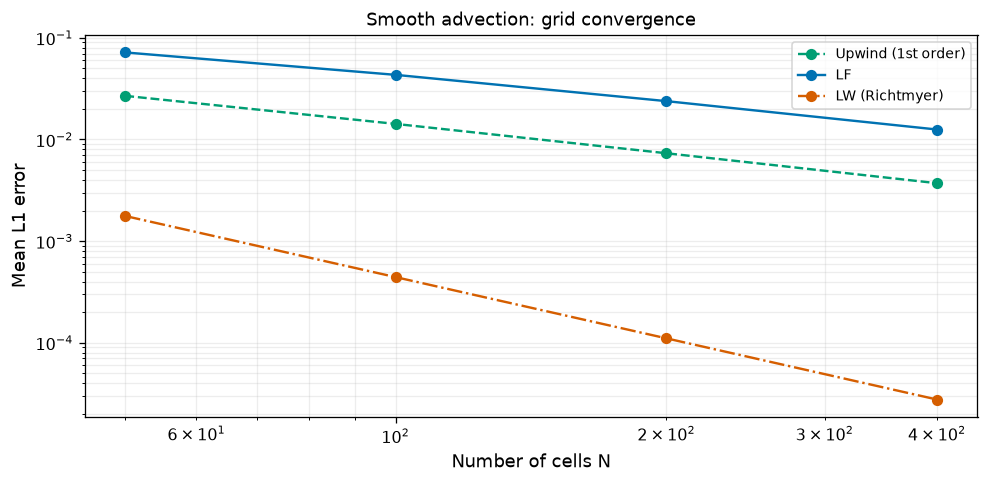

method,N,L1,p_observed
Upwind (1st order),50,0.02687,—
Upwind (1st order),100,0.01422,0.9176
Upwind (1st order),200,0.007321,0.9581
Upwind (1st order),400,0.003715,0.9788
LF,50,0.07184,—
LF,100,0.04322,0.733
LF,200,0.02384,0.8586
LF,400,0.01253,0.9273
LW (Richtmyer),50,0.001766,—
LW (Richtmyer),100,0.000442,1.999


CFL=1: exact one-cell shift for both signs of a.


In [5]:
if CFG["run_convergence"]:
    rows = []
    fig, ax = plt.subplots(figsize=(8.7, 4.3))
    for method in ("Upwind", "LF", "LW"):
        previous = None
        errors = []
        for n in CFG["n_convergence"]:
            run = sc.simulate(sc.CASES["advection_sine"], method, n=n, cfl=CFG["cfl"])
            RUNS.append(run)
            row = sc.metrics(run)
            row["p_observed"] = np.nan if previous is None else np.log(previous["L1"] / row["L1"]) / np.log(n / previous["N"])
            rows.append(row)
            errors.append(row["L1"])
            previous = row
        ax.loglog(CFG["n_convergence"], errors, marker="o", color=sc.COLORS[method], ls=sc.STYLES[method], label=sc.LABELS[method])
    ax.set(xlabel="Number of cells N", ylabel="Mean L1 error", title="Smooth advection: grid convergence")
    ax.grid(which="both", alpha=0.22)
    ax.legend()
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    show_table(rows, ("method", "N", "L1", "p_observed"))

n = 64
q0 = np.random.default_rng(7).uniform(size=n)
ghost = np.pad(q0, 1, mode="wrap")
for speed in (-1.0, 1.0):
    for method in ("Upwind", "LF", "LW"):
        flux = sc.numerical_flux(ghost[:-1], ghost[1:], method, "advection", 1.0 / n, 1.0 / n, speed)
        np.testing.assert_allclose(q0 - np.diff(flux), np.roll(q0, int(speed)), atol=2e-14)
print("CFL=1: exact one-cell shift for both signs of a.")

## 3. 非粘性Burgers方程式：解自身が伝播速度になる

$$\frac{\partial q}{\partial t}+\frac{\partial}{\partial x}\left(\frac{q^2}{2}\right)=0.$$

滑らかな領域では$\frac{\partial q}{\partial t}+q \frac{\partial q}{\partial x}=0$なので、

$$\frac{dx}{dt}=q,\qquad \frac{dq}{dt}=0,\qquad x=\xi+tq_0(\xi).$$

線形移流と異なり、各特性曲線の速度$q_0(\xi)$が異なります。$\frac{dq_0}{d\xi}<0$では後方の速い波が前方の遅い波に追いつきます。

$$\frac{\partial q}{\partial x}=\frac{\frac{dq_0}{d\xi}}{1+t\frac{dq_0}{d\xi}},\qquad t_\mathrm{s}=-\frac{1}{\min_{\xi} \frac{dq_0}{d\xi}}.$$

$q_0=1+0.2\sin(2\pi x)$では$t_\mathrm{s}=1/(0.4\pi)\simeq0.7958$です。
$t<t_\mathrm{s}$では特性写像を二分法で逆にたどれますが、交差後の多価な曲線をそのまま物理的な解として使うことはできません。[S5]

**ここでは非粘性方程式を解きます。** 粘性Burgers方程式$\frac{\partial q}{\partial t}+q \frac{\partial q}{\partial x}=\nu \frac{\partial^2 q}{\partial x^2}$の拡散項は加えません。

First breaking time: 0.79577472


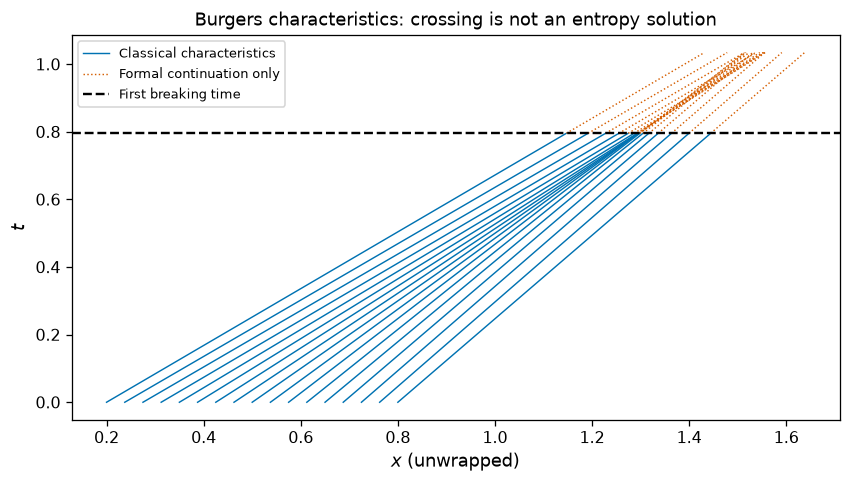

In [6]:
problem = sc.CASES["burgers_sine"]
ts = sc.breaking_time(problem)
print(f"First breaking time: {ts:.8f}")
fig, ax = plt.subplots(figsize=(7.5, 4.3))
t_pre = np.linspace(0.0, ts, 100)
t_post = np.linspace(ts, 1.3 * ts, 40)
for j, xi in enumerate(np.linspace(0.20, 0.80, 17)):
    q0 = problem.mean + problem.amplitude * np.sin(2.0 * np.pi * xi)
    ax.plot(xi + q0 * t_pre, t_pre, color="#0072B2", lw=0.9, label="Classical characteristics" if j == 0 else None)
    ax.plot(xi + q0 * t_post, t_post, color="#D55E00", lw=0.9, ls=":", label="Formal continuation only" if j == 0 else None)
ax.axhline(ts, color="black", ls="--", label="First breaking time")
ax.set(xlabel="$x$ (unwrapped)", ylabel="$t$", title="Burgers characteristics: crossing is not an entropy solution")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

### 3.1 滑らかな解の検証と衝撃波形成後の表示

$t=0.4<t_\mathrm{s}$では、逆特性写像から得た厳密解と比較します。
セル平均は$\frac{dQ_0}{d\xi}=q_0$として

$$\int_{x_L}^{x_R}q(x,t)\,dx=\left[Q_0(\xi)+\frac t2 q_0(\xi)^2\right]_{\xi_L}^{\xi_R}$$

で求めます。この式は$dx=(1+t\frac{dq_0}{d\xi})d\xi$から導けます。
$t\ge t_\mathrm{s}$の正弦波にはこの逆写像を使わず、数値解だけを表示します。**衝撃波形成後の数値解を厳密解とは呼びません。**

Godunov流束の具体式は次節で導出します。

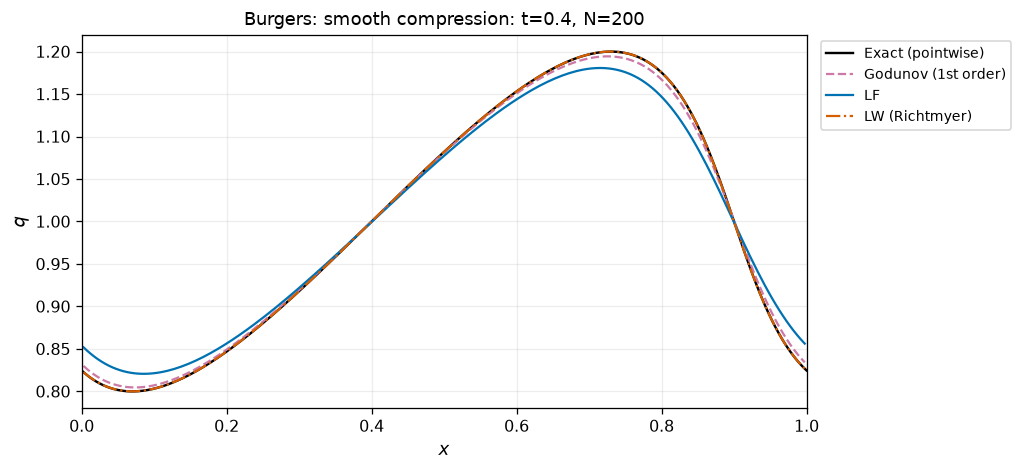

method,L1,TV,balance
Godunov (1st order),0.003601,0.7795,0
LF,0.01342,0.7199,0
LW (Richtmyer),6.56e-05,0.7999,0


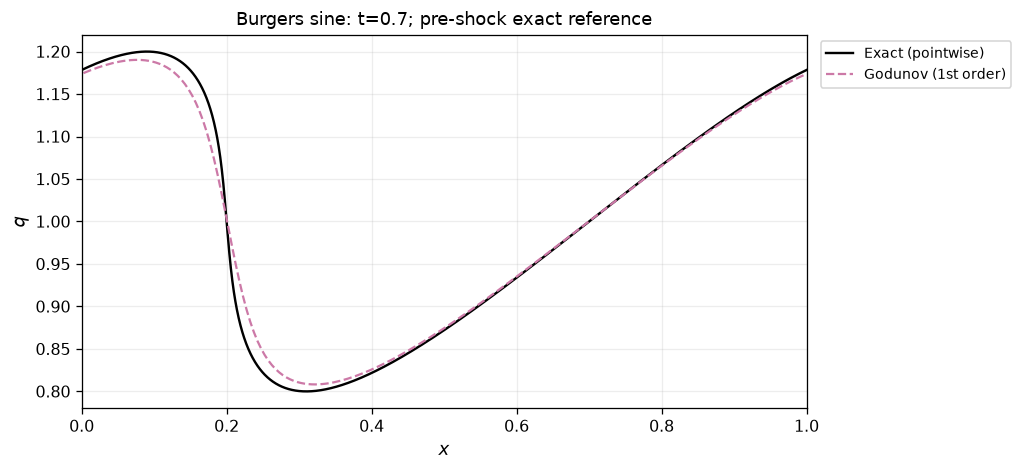

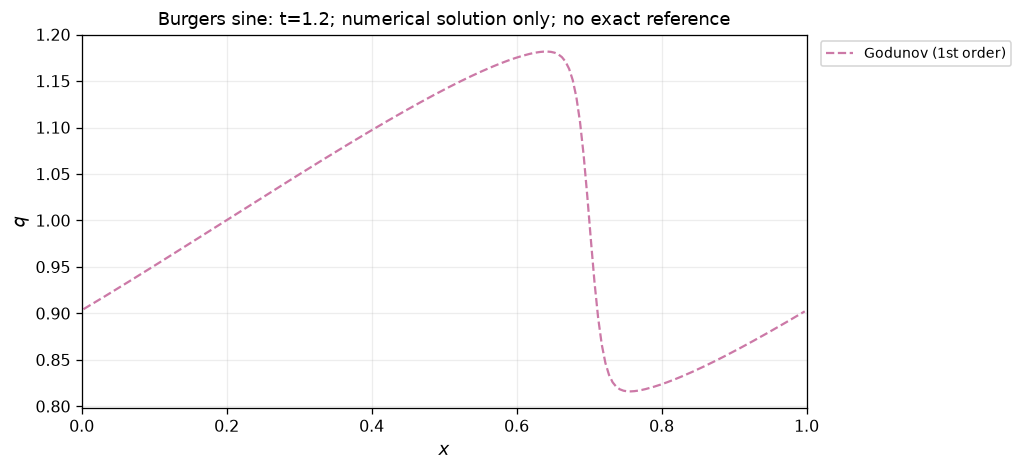

In [7]:
problem = sc.CASES["burgers_sine"]
results = [sc.simulate(problem, method, n=CFG["n"], cfl=CFG["cfl"]) for method in ("Godunov", "LF", "LW")]
RUNS.extend(results)
sc.plot_profiles(results)
show_table([sc.metrics(r) for r in results], ("method", "L1", "TV", "balance"))
for t in (0.7, 1.2):
    result = sc.simulate(problem, "Godunov", n=CFG["n"], cfl=CFG["cfl"], t_end=t)
    RUNS.append(result)
    note = "pre-shock exact reference" if t < sc.breaking_time(problem) else "numerical solution only; no exact reference"
    sc.plot_profiles([result], title=f"Burgers sine: t={t:g}; {note}")

## 4. 不連続を含む解：保存形とRankine–Hugoniot条件

微分形$\frac{\partial q}{\partial t}+q \frac{\partial q}{\partial x}=0$の積$q \frac{\partial q}{\partial x}$は不連続点で通常の微分として扱えません。
そこで積分の保存則を満たす**弱解**を考えます。速度$s$で動く不連続の前後の収支から、

$$s(q_R-q_L)=f(q_R)-f(q_L),\qquad s=\frac{q_L+q_R}{2}$$

を得ます。$q_L=1,q_R=0$なら$s=0.5$です。

セル中心の$q_i$で非保存形$q \frac{\partial q}{\partial x}$を風上差分するだけでは、この衝撃波速度を保証できません。
**保存形で共通の境界流束を使うこと**が重要です。ただし保存性だけでは、次節のエントロピー条件までは保証できません。[S4, S5]

### 4.1 リーマン問題：衝撃波と希薄波

初期の不連続を$x=x_0$に置き、左状態$q_L$と右状態$q_R$を与えます。

**$q_L>q_R$：圧縮的な衝撃波**

$$q(x,t)=\begin{cases}q_L,&x<x_0+st,\\q_R,&x>x_0+st,\end{cases}\qquad q_L>s>q_R.$$

左右から特性曲線が衝撃波へ流れ込みます。

**$q_L<q_R$：希薄波**

$$q(x,t)=\begin{cases}q_L,&(x-x_0)/t\le q_L,\\(x-x_0)/t,&q_L<(x-x_0)/t<q_R,\\q_R,&(x-x_0)/t\ge q_R.\end{cases}$$

$q_L=-1,q_R=1$では、間が連続的に広がり、中央は$q=0$です。
Burgersの凸流束では、増加する不連続を衝撃波として残す弱解はエントロピー条件に反します。[S5, S6]

数学的エントロピーの一例は$\eta(q)=q^2/2$、対応する流束は$\psi(q)=q^3/3$で、$\frac{\partial\eta}{\partial t}+\frac{\partial\psi}{\partial x}\le0$を要求します。
これは気体の熱力学的エントロピーそのものではなく、消散に整合した弱解を選ぶ条件です。

### 4.2 Godunov法：セル境界で何が流れるか

各セルを区分一定とみなし、その境界のリーマン問題を解き、$x/t=0$の流束を使います。
凸流束$f(q)=q^2/2$では、

$$F^*_G(q_L,q_R)=\begin{cases}\min_{q_L\le q\le q_R} f(q),&q_L\le q_R,\\\max_{q_R\le q\le q_L} f(q),&q_L>q_R.\end{cases}$$

具体的には、希薄波で$q_L\ge0$なら$f(q_L)$、$q_R\le0$なら$f(q_R)$、$q_L<0<q_R$なら0です。
衝撃波では$s\ge0$なら$f(q_L)$、$s<0$なら$f(q_R)$です。

**平均速度の符号だけでは、音速点$q=0$をまたぐ希薄波を正しく扱えません。**
この処理が、単純な片側差分からリーマン問題に基づく風上法へ進む理由です。
LF・LWも$f(q)=q^2/2$を代入して同じ保存形の更新に使います。[S4, S5]

qL,qR,wave,Godunov flux
1,2,rarefaction,0.5
-2,-1,rarefaction,0.5
-1,1,rarefaction,0
1,0,shock,0.5
2,1,shock,2
-1,-2,shock,2


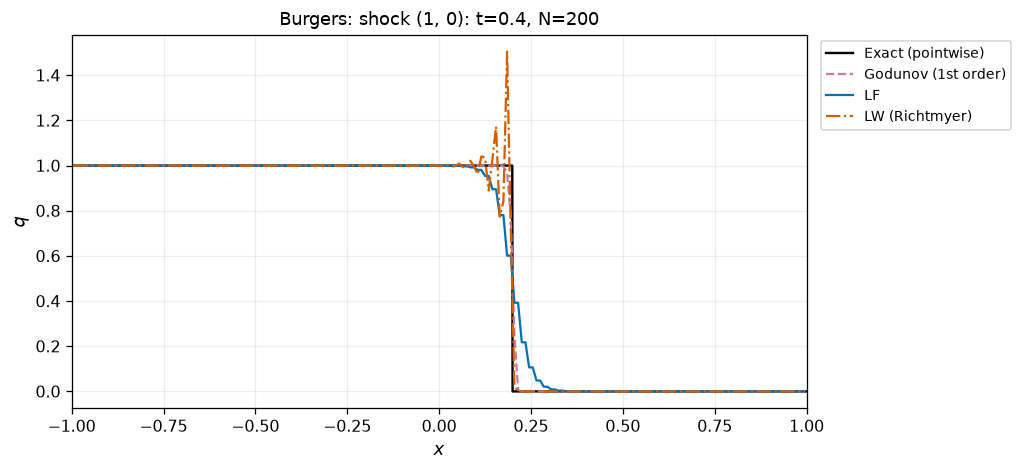

method,L1,TV,undershoot,overshoot,balance
Godunov (1st order),0.002558,1,0,0,-1.11e-16
LF,0.016,1,0,0,1.665e-16
LW (Richtmyer),0.008398,3.295,0,0.5049,1.665e-16


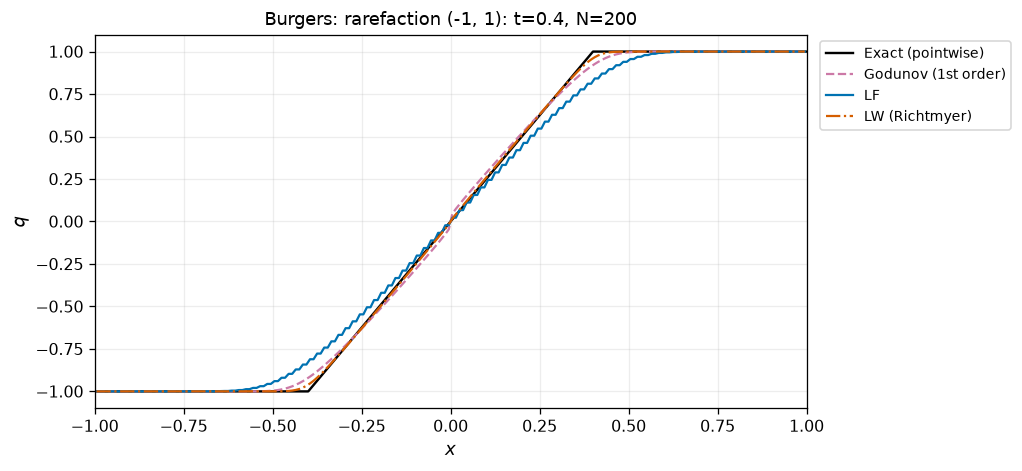

method,L1,TV,undershoot,overshoot,balance
Godunov (1st order),0.0147,2,0,0,0
LF,0.04035,2,0,0,1.421e-16
LW (Richtmyer),0.003987,2,0,0,0


In [8]:
rows = []
for left, right in ((1.0, 2.0), (-2.0, -1.0), (-1.0, 1.0), (1.0, 0.0), (2.0, 1.0), (-1.0, -2.0)):
    flux = sc.numerical_flux(left, right, "Godunov", "burgers", 0.01, 0.1)
    rows.append({"qL": left, "qR": right, "wave": "rarefaction" if left < right else "shock", "Godunov flux": float(flux)})
show_table(rows)
for key in ("burgers_shock", "burgers_rarefaction"):
    problem = sc.CASES[key]
    results = [sc.simulate(problem, method, n=CFG["n"], cfl=CFG["cfl"]) for method in ("Godunov", "LF", "LW")]
    RUNS.extend(results)
    sc.plot_profiles(results)
    show_table([sc.metrics(r) for r in results], ("method", "L1", "TV", "undershoot", "overshoot", "balance"))

### 4.3 衝撃波速度を測る

$(q_L,q_R)=(1,0)$の問題で、全量から**質量等価位置**

$$x_\mathrm{mass}=x_\min+\frac{\int q\,dx-q_R(x_\max-x_\min)}{q_L-q_R}$$

を求めます。これは保存収支を測る量で、衝撃波の幅や形が正しいことまで証明するものではありません。
ここでは境界に波が達する前なので、厳密な位置は$x_0+st$です。

**問い：** 同じ衝撃波位置でも、LFとGodunovの波面の幅は同じでしょうか。

In [9]:
problem = sc.CASES["burgers_shock"]
rows = []
for method in ("Godunov", "LF", "LW"):
    for t in (0.2, 0.4):
        result = sc.simulate(problem, method, n=CFG["n"], cfl=CFG["cfl"], t_end=t)
        RUNS.append(result)
        xmass = sc.shock_position(result)
        exact = problem.x0 + 0.5 * (problem.left + problem.right) * t
        rows.append({"method": sc.LABELS[method], "t": t, "x_mass": xmass, "x_exact": exact, "position_error": xmass - exact, "speed_from_mass": (xmass - problem.x0) / t})
show_table(rows)

method,t,x_mass,x_exact,position_error,speed_from_mass
Godunov (1st order),0.2,0.1,0.1,8.327e-17,0.5
Godunov (1st order),0.4,0.2,0.2,-2.776e-16,0.5
LF,0.2,0.1,0.1,-1.388e-16,0.5
LF,0.4,0.2,0.2,-2.776e-16,0.5
LW (Richtmyer),0.2,0.1,0.1,8.327e-17,0.5
LW (Richtmyer),0.4,0.2,0.2,-2.776e-16,0.5


### 4.4 保存するだけでは不十分：膨張衝撃波の反例

BurgersのRoe平均速度は$\tilde a=(q_L+q_R)/2$で、補正なしの流束は

$$F^*_{\mathrm{Roe}}=\frac{f(q_L)+f(q_R)}2-\frac{|\tilde a|}2(q_R-q_L).$$

$(-1,1)$では$\tilde a=0$なので$F^*_{\mathrm{Roe}}=1/2$ですが、Godunov流束は0です。
前者は境界の不連続を残すため、**保存則を満たしても希薄波という正しいエントロピー解にはなりません**。
以下の `Roe_no_efix` はこの失敗を調べるための実装です。[S5, S6]

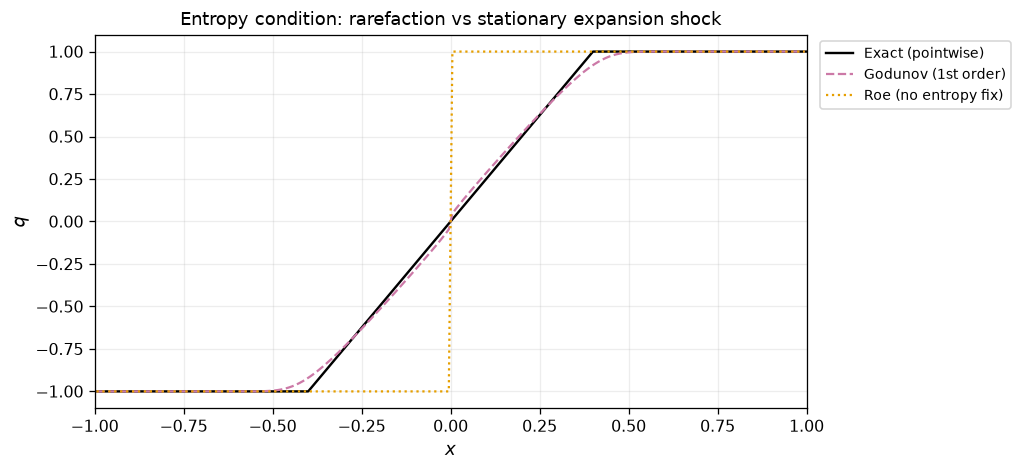

method,L1,TV,balance
Godunov (1st order),0.0147,2,0
Roe (no entropy fix),0.2,2,0


In [10]:
problem = sc.CASES["burgers_rarefaction"]
entropy_runs = [sc.simulate(problem, method, n=CFG["n"], cfl=CFG["cfl"]) for method in ("Godunov", "Roe_no_efix")]
RUNS.extend(entropy_runs)
sc.plot_profiles(entropy_runs, title="Entropy condition: rarefaction vs stationary expansion shock")
show_table([sc.metrics(r) for r in entropy_runs], ("method", "L1", "TV", "balance"))

## 5. Euler方程式とは何が共通で、何が異なるか

Euler方程式も$\frac{\partial\boldsymbol U}{\partial t}+\frac{\partial\boldsymbol F(\boldsymbol U)}{\partial x}=0$という保存則ですが、未知量は$(\rho,\rho u,E)$の3成分です。
滑らかな流れの連続の式は

$$\frac{\partial\rho}{\partial t}+u\frac{\partial\rho}{\partial x}=-\rho \frac{\partial u}{\partial x}.$$

左辺は流れに沿う変化、右辺は圧縮・膨張です。$u=u_0,p=p_0$が一定なら、密度分布は線形移流に従うEuler方程式の厳密な解になります。
第II部のエントロピー波・接触面移流は、この性質を利用する問題です。[S1, S7]

運動方程式$\frac{\partial u}{\partial t}+u \frac{\partial u}{\partial x}=-\frac{1}{\rho}\frac{\partial p}{\partial x}$にはBurgersと同じ非線形項がありますが、**圧力を単純に無視すれば一般の気体流れがBurgersになるわけではありません**。
滑らかな理想気体では$\frac{Dp}{Dt}=-\gamma p \frac{\partial u}{\partial x}$であり、初期に$\frac{\partial p}{\partial x}=0$でも後で圧力勾配が生じ得ます。
Burgersは非線形波の急峻化を分離したモデルです。形式的な無圧力極限での速度方程式との関係は、特性の交差前に限って考え、衝撃波を含む気体の質量・運動量・エネルギー保存則と同一視しません。

Eulerの3つの特性速度は$u-c,u,u+c$です。**風上の考え方はEulerにも使えますが、流速$u$の符号だけで全成分の差分方向を選ぶことはできません。** 第II部でこの3波の関係を詳しく調べます。[S7]

## 時間発展の動画

標準では `movie_case` の時間発展を表示します。動画を省略する場合は `run_movies=False` にします。
各方式の受理済み状態を保存し、共通のフレーム時刻にだけ線形補間します。補間値を次の時間積分には使いません。
軸範囲は動画全体で固定します。正弦波Burgersの衝撃波形成後には厳密解の線を表示しません。
JavaScript表示なので、この機能にはffmpegは不要です。

In [11]:
if CFG["run_movies"]:
    problem = sc.CASES[CFG["movie_case"]]
    methods = ("Upwind", "LF", "LW") if problem.equation == "advection" else ("Godunov", "LF", "LW")
    movie_runs = [sc.simulate(problem, method, n=CFG["n"], cfl=CFG["cfl"], record=True) for method in methods]
    for run in movie_runs:
        plain = sc.simulate(problem, run["scheme"], n=CFG["n"], cfl=CFG["cfl"])
        np.testing.assert_array_equal(run["q"], plain["q"])
        assert run["steps"] == plain["steps"] and run["exchange"] == plain["exchange"]
    display(sc.animate(movie_runs, frames=CFG["movie_frames"]))

## 任意：CFL数と非保存形の反例

前半では線形移流のCFL数だけを変えます。LFでは$\Delta t$を小さくすると、流束の人工的な散逸係数$\Delta x/\Delta t$が大きくなります。

後半は**正しい解法ではありません**。$q_i^{n+1}=q_i^n-(\Delta t/\Delta x)q_i^n(q_i^n-q_{i-1}^n)$を、$(q_L,q_R)=(1,0)$へ適用します。
右側の$q_i=0$では更新が0になり、正しい速度0.5の衝撃波が進みません。有限差分式が滑らかな方程式を近似していても、不連続解には保存形が必要であることを確認します。

In [12]:
if CFG["run_extras"]:
    rows = []
    for method in ("Upwind", "LF", "LW"):
        for cfl in (0.2, 0.4, 0.8, 1.0):
            run = sc.simulate(sc.CASES["advection_sine"], method, n=CFG["n"], cfl=cfl)
            RUNS.append(run)
            rows.append(sc.metrics(run))
    show_table(rows, ("method", "CFL", "L1", "balance"))
    problem = sc.CASES["burgers_shock"]
    edges = np.linspace(*problem.bounds, CFG["n"] + 1)
    dx = edges[1] - edges[0]
    q = sc.exact_cell_average(problem, edges, 0.0)
    t = 0.0
    while t < problem.final_time:
        dt = min(CFG["cfl"] * dx / max(abs(q).max(), 1e-12), problem.final_time - t)
        left = np.r_[q[0], q[:-1]]
        q = q - (dt / dx) * q * (q - left)
        t += dt
    x_mass = problem.bounds[0] + (dx * q.sum() - problem.right * np.ptp(problem.bounds)) / (problem.left - problem.right)
    print("Deliberately nonconservative counterexample:")
    print("Computed x_mass =", x_mass, "; correct shock position =", 0.5 * problem.final_time)

## 結果の保存・確認問題

`metrics.csv` に誤差・全変動・保存残差を、`states.npz` に各計算の初期値・最終値・履歴を保存します。
正弦波Burgersの衝撃波形成後など、厳密解を評価しない条件の誤差は `NaN` とします。

1. 移流速度が負の場合に、左差分を使うと何が問題になりますか。
2. $|C|=1$だけでは精度比較ができない理由を、更新式から説明してください。
3. $q_L=2,q_R=-1$の衝撃波速度とGodunov流束を求めてください。
4. 保存則とエントロピー条件は、それぞれ何を決めますか。
5. Euler方程式で$u=0$でも左右へ情報が伝わるのはなぜでしょうか。

次は [第II部：Euler方程式の古典的数値解法](02_euler_classical.ipynb) で、同じ保存形の更新を3成分の連立系に適用します。

In [13]:
if CFG["export_results"]:
    sc.export_results(RUNS, OUTPUT_DIR)
    print(f"Saved {len(RUNS)} runs to {OUTPUT_DIR}")

Saved 40 runs to /home/runner/work/euler1d-scheme-comparison/euler1d-scheme-comparison/four_part_outputs/scalar


## 参考文献・実装の確認先

[S1] Clawpack, *Advection*：連続の式、線形移流、特性曲線。  
https://www.clawpack.org/riemann_book/html/Advection.html

[S2] Clawpack, *One-dimensional advection*：一次風上法、LW、数値拡散・振動。  
https://www.clawpack.org/gallery/_static/apps/notebooks/classic/advection_1d/advection_1d.html

[S3] Per-Olof Persson, *Finite Difference Methods for PDEs*：LF・LW・風上法、修正方程式。  
https://persson.berkeley.edu/math228b/html/finite_difference_methods_for_PDEs.html

[S4] Clawpack, *Approximate solvers*：保存形の数値流束とGodunov法。  
https://www.clawpack.org/riemann_book/html/Approximate_solvers.html

[S5] Ketcheson, D. I., LeVeque, R. J., & del Razo, M. J., *Riemann Problems and Jupyter Solutions*, Burgers' equation.  
https://www.clawpack.org/riemann_book/html/Burgers.html

[S6] Uppsala University, *Entropy fix*：Burgersの音速点をまたぐ希薄波とRoe流束の問題。  
https://www.astro.uu.se/~bf/course/numhd_course/3_2_9Entropy_fix.html

[S7] Clawpack, *The Euler equations of gas dynamics*：保存則、音波、接触・エントロピー波。  
https://www.clawpack.org/riemann_book/html/Euler.html

数値実装は本教材の保存形更新と解析式に基づきます。Clawpack自体を呼び出すコードではありません。